<a href="https://colab.research.google.com/github/amouadeb/Aula6/blob/main/Pond.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Instalando Bibliotecas e Dependencias**


In [ ]:

# Instalar biblioteca para coletar dados financeiros
!pip -q install yfinance

# Importar bibliotecas
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar visualização
sns.set_theme(style="whitegrid")

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


In [ ]:

# ATIVIDADE DE PROGRAMAÇÃO — RA FINAL 3

# Carteira fornecida pelo professor
# Preencher durante a aula

ativos = ["PETR4.SA", "VALE3.SA", "ITUB4.SA", "WEGE3.SA"]

# Pesos de cada ativo na carteira
# Exemplo: 40% = 0.40

pesos = [0.40, 0.30, 0.20, 0.10]

# Garantir soma dos pesos = 100
print("Total dos pesos:", sum(pesos) * 100, "%")


Total dos pesos: 100.0 %


Período: 2024-11-10 até 2026-11-10


Ticker,PETR4.SA,VALE3.SA,ITUB4.SA,WEGE3.SA
Date,,,,
2024-11-11,28.352453,49.960136,26.441256,52.188137
2024-11-12,28.884308,48.827198,26.125046,52.122303
2024-11-13,28.845201,48.690903,25.989525,51.445152
2024-11-14,29.150236,48.418316,25.914240,51.115971
2024-11-18,29.877621,49.023117,25.823891,50.786804



Quantidade de registros por ativo:
Ticker
PETR4.SA    496
VALE3.SA    496
ITUB4.SA    496
WEGE3.SA    496
dtype: int64


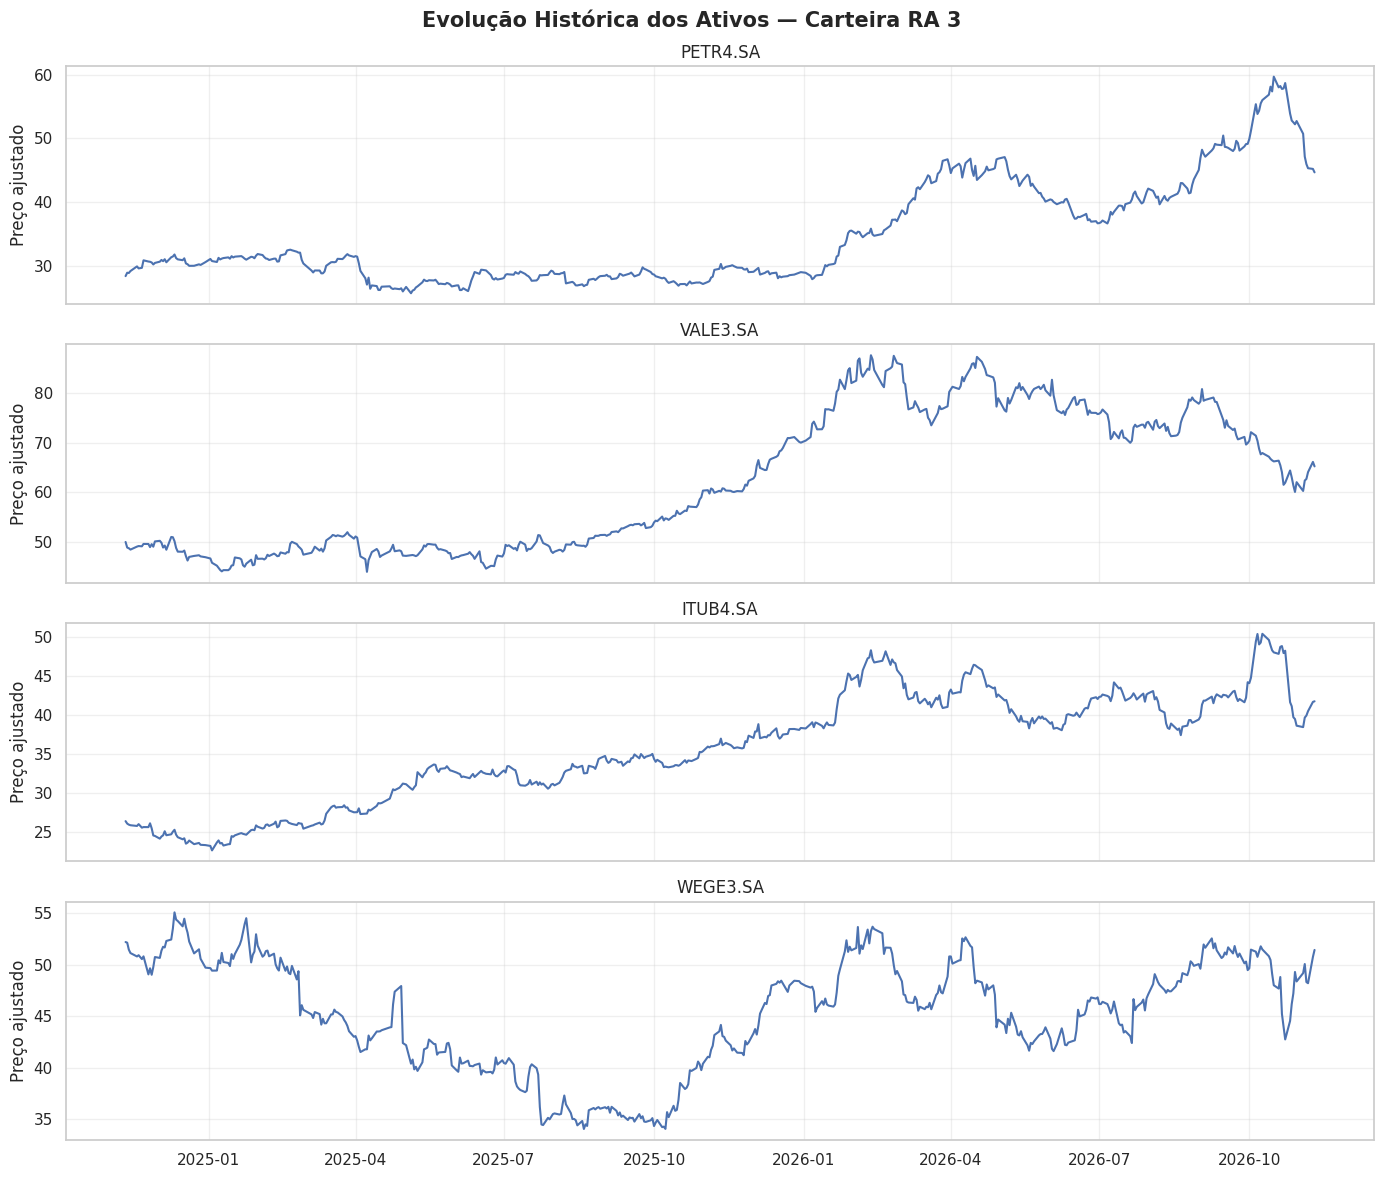

Dados ausentes por ativo:
Ticker
PETR4.SA    0
VALE3.SA    0
ITUB4.SA    0
WEGE3.SA    0
dtype: int64


In [ ]:

# ETAPA 3 — COLETA DE DADOS

# Definir período de 24 meses
data_fim = pd.Timestamp.today().normalize()
data_inicio = data_fim - pd.DateOffset(months=24)

# Baixar os preços históricos ajustados
precos = yf.download(
    ativos,
    start=data_inicio.strftime("%Y-%m-%d"),
    end=(data_fim + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
    auto_adjust=True,
    progress=False
)["Close"]

# Organizar as colunas
precos = precos.reindex(columns=ativos)

# Exibir os primeiros registros
print("Período:", data_inicio.date(), "até", data_fim.date())
display(precos.head())

# Conferir quantidade de dados disponíveis
print("\nQuantidade de registros por ativo:")
print(precos.count())


# GRÁFICOS — EVOLUÇÃO DOS PREÇOS DOS ATIVOS

fig, eixos = plt.subplots(
    len(ativos), 1,
    figsize=(14, 3 * len(ativos)),
    sharex=True,
    squeeze=False
)

for i, ativo in enumerate(ativos):
    eixos[i, 0].plot(
        precos.index,
        precos[ativo],
        linewidth=1.5
    )

    eixos[i, 0].set_title(ativo, fontsize=12)
    eixos[i, 0].set_ylabel("Preço ajustado")
    eixos[i, 0].grid(True, alpha=0.3)

plt.suptitle(
    "Evolução Histórica dos Ativos — Carteira RA 3",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Verificar dados ausentes
print("Dados ausentes por ativo:")
print(precos.isna().sum())



In [ ]:

# ETAPA 4 — CALCULAR RETORNOS DIÁRIOS

# Remover datas com preços faltantes
precos = precos.dropna()

# Calcular a variação percentual diária
retornos = precos.pct_change().dropna()

# Mostrar os primeiros retornos em porcentagem
print("Retornos diários dos ativos (%):")
display((retornos.head() * 100).round(2))

# Conferir a quantidade de observações
print("Quantidade de retornos:", len(retornos))


Retornos diários dos ativos (%):


Ticker,PETR4.SA,VALE3.SA,ITUB4.SA,WEGE3.SA
Date,,,,
2024-11-12,1.88,-2.27,-1.20,-0.13
2024-11-13,-0.14,-0.28,-0.52,-1.30
2024-11-14,1.06,-0.56,-0.29,-0.64
2024-11-18,2.50,1.25,-0.35,-0.64
2024-11-19,-1.05,0.23,0.90,0.24


Quantidade de retornos: 495


Matriz de Correlação:


Ticker,PETR4.SA,VALE3.SA,ITUB4.SA,WEGE3.SA
Ticker,,,,
PETR4.SA,1.00,0.05,0.22,-0.01
VALE3.SA,0.05,1.00,0.24,0.23
ITUB4.SA,0.22,0.24,1.00,0.20
WEGE3.SA,-0.01,0.23,0.20,1.00


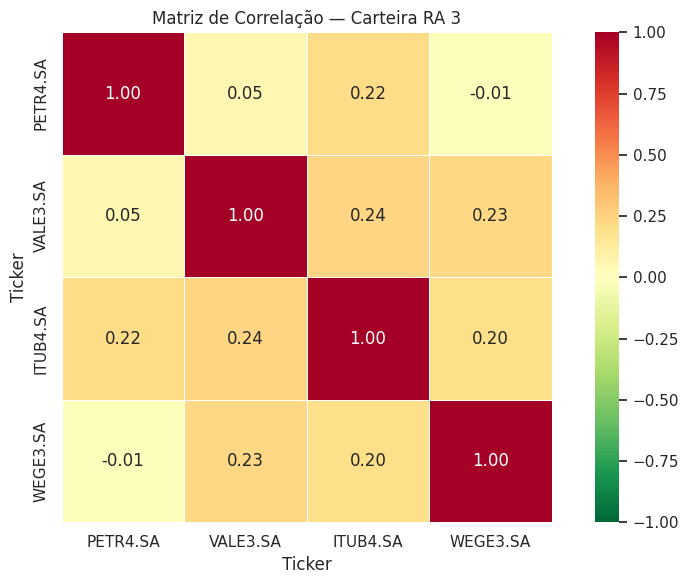

In [ ]:

# ETAPA 5 — MATRIZ DE CORRELAÇÃO

# Calcular a correlação de Pearson entre os retornos
matriz_correlacao = retornos.corr()

# Mostrar a matriz numérica
print("Matriz de Correlação:")
display(matriz_correlacao.round(2))

# Criar o mapa de calor
plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Matriz de Correlação — Carteira RA 3")
plt.tight_layout()
plt.show()


Matriz de Covariância (p.p.²):


Ticker,PETR4.SA,VALE3.SA,ITUB4.SA,WEGE3.SA
Ticker,,,,
PETR4.SA,2.9653,0.1426,0.6252,-0.0273
VALE3.SA,0.1426,2.6420,0.6445,0.7331
ITUB4.SA,0.6252,0.6445,2.7597,0.6415
WEGE3.SA,-0.0273,0.7331,0.6415,3.8247


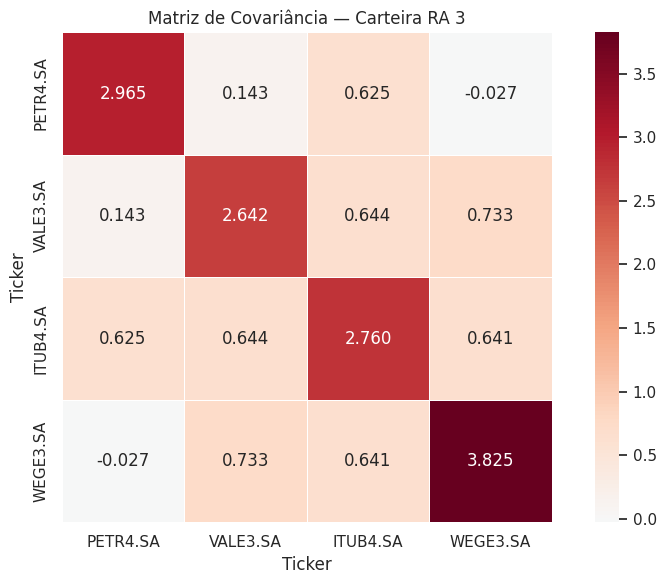

In [ ]:

# ETAPA 6 — MATRIZ DE COVARIÂNCIA

# Calcular a covariância amostral dos retornos
matriz_covariancia = retornos.cov()

# Converter para pontos percentuais ao quadrado
covariancia_pp = matriz_covariancia * 10000

# Exibir a matriz
print("Matriz de Covariância (p.p.²):")
display(covariancia_pp.round(4))

# Criar o mapa de calor
plt.figure(figsize=(9, 6))

sns.heatmap(
    covariancia_pp,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Matriz de Covariância — Carteira RA 3")
plt.tight_layout()
plt.show()


In [ ]:

# ETAPA 7 — RISCO TOTAL DA CARTEIRA

# Transformar os pesos em um vetor
w = np.array(pesos, dtype=float)

# Conferir os pesos
assert len(w) == len(ativos), "Quantidade de pesos diferente da quantidade de ativos."
assert np.isclose(w.sum(), 1), "Os pesos precisam somar 100%."

# Organizar a matriz na ordem da carteira
sigma = matriz_covariancia.loc[ativos, ativos].to_numpy()

# Calcular a variância da carteira: wT * Sigma * w
variancia_carteira = w.T @ sigma @ w

# Calcular o desvio-padrão diário da carteira
risco_diario = np.sqrt(variancia_carteira)

# Anualizar o risco considerando 252 pregões
risco_anual = risco_diario * np.sqrt(252)

print(f"Variância diária da carteira: {variancia_carteira:.6f}")
print(f"Risco diário da carteira: {risco_diario * 100:.2f}%")
print(f"Volatilidade anualizada: {risco_anual * 100:.2f}%")


Variância diária da carteira: 0.000114
Risco diário da carteira: 1.07%
Volatilidade anualizada: 16.95%


In [ ]:

# ETAPA 8 — BENEFÍCIO DA DIVERSIFICAÇÃO

# Calcular o desvio-padrão diário de cada ativo
volatilidades = retornos[ativos].std()

# Média ponderada dos riscos individuais
risco_sem_diversificacao = np.dot(w, volatilidades)

# Benefício percentual da diversificação
beneficio = (
    1 - risco_diario / risco_sem_diversificacao
) * 100

print("Risco sem benefício de diversificação:",
      f"{risco_sem_diversificacao * 100:.2f}%")

print("Risco da carteira observada:",
      f"{risco_diario * 100:.2f}%")

print("Redução do risco pela diversificação:",
      f"{beneficio:.2f}%")


Risco sem benefício de diversificação: 1.70%
Risco da carteira observada: 1.07%
Redução do risco pela diversificação: 37.35%


In [ ]:

# ETAPA 9 — SHARPE, BETA, TREYNOR E ALFA DE JENSEN

import requests

# 1. Definir o mesmo período dos ativos
inicio = precos.index.min()
fim = precos.index.max()

# 2. Baixar o Ibovespa
ibov_dados = yf.download(
    "^BVSP",
    start=inicio.strftime("%Y-%m-%d"),
    end=(fim + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
    auto_adjust=True,
    progress=False
)

ibov_precos = ibov_dados["Close"]

if isinstance(ibov_precos, pd.DataFrame):
    ibov_precos = ibov_precos.iloc[:, 0]

retorno_ibov = ibov_precos.pct_change().dropna()
retorno_ibov.name = "Ibovespa"

# 3. Buscar o CDI diário no Banco Central
url = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados"

resposta = requests.get(
    url,
    params={
        "formato": "json",
        "dataInicial": inicio.strftime("%d/%m/%Y"),
        "dataFinal": fim.strftime("%d/%m/%Y")
    },
    timeout=30
)

resposta.raise_for_status()
dados_cdi = pd.DataFrame(resposta.json())

if dados_cdi.empty:
    raise ValueError("CDI não encontrado para o período.")

cdi = pd.Series(
    pd.to_numeric(
        dados_cdi["valor"].str.replace(",", "."),
        errors="coerce"
    ).to_numpy() / 100,
    index=pd.to_datetime(
        dados_cdi["data"],
        format="%d/%m/%Y"
    ),
    name="CDI"
)

# 4. Calcular retornos diários da carteira
retorno_carteira = (
    retornos[ativos] @ np.array(pesos)
).rename("Carteira")

# 5. Alinhar todas as séries nas mesmas datas
base = pd.concat(
    [retorno_carteira, retorno_ibov, cdi],
    axis=1
).dropna()

if len(base) < 60:
    raise ValueError("Poucas datas comuns para a análise.")

# Retornos acima do CDI
excesso_carteira = base["Carteira"] - base["CDI"]
excesso_ibov = base["Ibovespa"] - base["CDI"]

# 6. Índice de Sharpe anualizado
sharpe = (
    excesso_carteira.mean()
    / excesso_carteira.std()
) * np.sqrt(252)

# Sharpe do Ibovespa para comparação
sharpe_ibov = (
    excesso_ibov.mean()
    / excesso_ibov.std()
) * np.sqrt(252)

# 7. Beta em relação ao Ibovespa
beta = (
    excesso_carteira.cov(excesso_ibov)
    / excesso_ibov.var()
)

# 8. Índice de Treynor anualizado
if beta > 0.05:
    treynor = excesso_carteira.mean() * 252 / beta
else:
    treynor = np.nan

# 9. Alfa de Jensen pelo CAPM
alfa_diario = (
    excesso_carteira - beta * excesso_ibov
).mean()

alfa_anual = alfa_diario * 252

# 10. Apresentar resultados
print("INDICADORES DE DESEMPENHO — RA 3")
print("-" * 45)
print(f"Observações utilizadas: {len(base)}")
print(f"Sharpe da carteira: {sharpe:.3f}")
print(f"Sharpe do Ibovespa: {sharpe_ibov:.3f}")
print(f"Beta da carteira: {beta:.3f}")

if np.isfinite(treynor):
    print(f"Treynor anualizado: {treynor * 100:.2f}%")
else:
    print("Treynor: não interpretável (beta baixo ou negativo)")

print(f"Alfa de Jensen anualizado: {alfa_anual * 100:.2f}%")


INDICADORES DE DESEMPENHO — RA 3
---------------------------------------------
Observações utilizadas: 494
Sharpe da carteira: 0.517
Sharpe do Ibovespa: 0.200
Beta da carteira: 0.649
Treynor anualizado: 13.51%
Alfa de Jensen anualizado: 6.12%


**Interpretaçao**


- Sharpe: quanto maior, melhor foi a remuneração pelo risco total. Compare também com o Sharpe do Ibovespa.
- Beta: acima de 1 indica maior sensibilidade ao mercado; entre 0 e 1 indica menor sensibilidade positiva.
- Treynor: mede retorno excedente por unidade de beta. Seu valor exige cuidado quando o beta é pequeno ou negativo.
- Alfa de Jensen: positivo indica desempenho acima do previsto pelo CAPM; negativo, abaixo. Isso é histórico, não garantia futura.